<a href="https://colab.research.google.com/github/sidcodes2727/ML-labs/blob/main/MLLab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub

path = kagglehub.dataset_download("uciml/mushroom-classification")
print(path)

Using Colab cache for faster access to the 'mushroom-classification' dataset.
/kaggle/input/mushroom-classification


In [ ]:
df = pd.read_csv('/kaggle/input/mushroom-classification/mushrooms.csv')

print(df.shape)
print(df.columns)
print(df.duplicated().sum())
print(df.isnull().sum())
df

(8124, 23)
Index(['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='object')
0
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number  

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l


In [ ]:
req = df["stalk-root"].mode()[0]
df["stalk-root"] = df["stalk-root"].replace("?", req)
df

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l


In [ ]:
from sklearn.preprocessing import OneHotEncoder

columns = df.drop(columns=['class']).columns.tolist()

for col in columns:
    enc= OneHotEncoder()
    encoded= enc.fit_transform(df[[col]]).toarray()
    enc_df= pd.DataFrame(encoded,columns=[col + str(i) for i in range(encoded.shape[1])])

    df= df.drop(columns=[col])
    df= df.join(enc_df)

In [ ]:
df

,class,cap-shape0,cap-shape1,cap-shape2,cap-shape3,cap-shape4,cap-shape5,cap-surface0,cap-surface1,cap-surface2,...,population3,population4,population5,habitat0,habitat1,habitat2,habitat3,habitat4,habitat5,habitat6
0,p,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,e,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,e,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,p,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,e,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8120,e,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8121,e,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8122,p,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
df['class'] = df['class'].map({'e':0,'p':1})
df

,class,cap-shape0,cap-shape1,cap-shape2,cap-shape3,cap-shape4,cap-shape5,cap-surface0,cap-surface1,cap-surface2,...,population3,population4,population5,habitat0,habitat1,habitat2,habitat3,habitat4,habitat5,habitat6
0,1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8120,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8121,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8122,1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
X = df.drop(columns=["class"])
y = df["class"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [ ]:
X_train = X_train.values
X_test = X_test.values
y_train = y_train.values
y_test = y_test.values

In [ ]:
def relu(z):
    return np.maximum(0,z)

In [ ]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [ ]:
def relu_derivative(z):
    return (z > 0).astype(int)

In [ ]:
def nn(X,y,lr=0.01,epochs=1000):
    # 116 -> 20 -> 1
    m,n = X.shape
    hidden = 20
    # m*n , n*20 , 20*1 -> m*1
    W1= np.random.randn(n,hidden)*lr
    b1= np.zeros(hidden)
    W2= np.random.randn(hidden,1)*lr
    b2= 0
    errors=[]
    y=y.reshape(-1,1)

    for i in range(epochs):
        #   W1,b1      W2,b2
        # X -> Z1 -> A1 -> Z2 -> A2 -> L
        Z1= np.dot(X,W1)+b1
        A1= relu(Z1)

        Z2= np.dot(A1,W2)+b2
        p= sigmoid(Z2)

        error = -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

        errors.append(error)

        dZ2= p-y
        # dw2 -> dZ2* dZ2/dW2
        dW2= (1/m)*np.dot(A1.T,dZ2)
        # db2 -> dZ2* dZ2/db2
        db2= (1/m)*np.sum(dZ2)

        # dA1 -> dZ2* dZ2/dA1
        dA1= np.dot(dZ2,W2.T)
        # dZ1 -> dA1* dA1/dZ1
        dZ1= dA1*relu_derivative(Z1)

        #dW1 -> dZ1 * dZ1/dW1
        dW1= (1/m)*np.dot(X.T,dZ1)
        #db1 -> dZ1 * dZ1/db1
        db1= (1/m)*np.sum(dZ1,axis=0)

        W2 = W2-lr*dW2
        b2 = b2-lr*db2

        W1 = W1-lr*dW1
        b1 = b1-lr*db1

    return W1,b1,W2,b2,errors

In [ ]:
W1,b1,W2,b2,errors = nn(X_train,y_train,lr=0.01,epochs=4000)

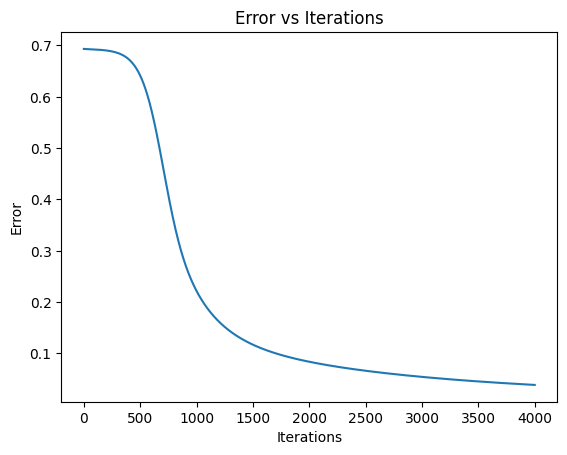

In [ ]:
plt.plot(errors)
plt.xlabel("Iterations")
plt.ylabel("Error")
plt.title("Error vs Iterations")
plt.show()

In [ ]:
def predict(X,W1,b1,W2,b2):

    Z1= np.dot(X,W1) + b1
    A1= relu(Z1)
    Z2= np.dot(A1,W2) + b2
    p= sigmoid(Z2)
    predictions= []

    for prob in p:
        if prob >= 0.5:
            predictions.append(1)
        else:
            predictions.append(0)

    return np.array(predictions)

In [ ]:
y_pred = predict(X_test,W1,b1,W2,b2)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1257
           1       0.99      0.98      0.99      1181

    accuracy                           0.99      2438
   macro avg       0.99      0.99      0.99      2438
weighted avg       0.99      0.99      0.99      2438



In [ ]:
from sklearn.neural_network import MLPClassifier

model = MLPClassifier(hidden_layer_sizes=(20,),max_iter=1000,random_state=42)
model.fit(X_train,y_train)

y_pred_lib= model.predict(X_test)

In [ ]:
print(classification_report(y_test,y_pred_lib))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1257
           1       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438

